# Forelesning 3: Deskriptiv statistikk i kjemi

Når vi gjentar en kjemisk måling, får vi sjelden nøyaktig samme resultat. I dag skal vi svare på tre spørsmål:

1. **Hvor ligger målingene?** Gjennomsnitt, median og persentiler
2. **Hvor mye varierer de?** Variasjonsbredde, interkvartilbredde, standardavvik og RSD
3. **Hvor sikkert kjenner vi gjennomsnittet?** Standardfeil og konfidensintervall

Målet er ikke å pugge formler, men å kunne velge riktig størrelse og tolke den kjemisk.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import t

## Del 1: Hvorfor varierer målinger?

Vi har målt jernkonsentrasjonen i den samme løsningen fem ganger:

```python
iron_mg_L = [5.12, 5.08, 5.15, 5.10, 5.13]
```

<div class="viktig">

Hva slags data vi har, bestemmer hvilken statistikk som passer:

- **Gjentatte målinger av samme prøve:** ofte gjennomsnitt og standardavvik
- **Målinger fra mange ulike prøver**, for eksempel nitrat i mange bekker: fordelingen er ofte skjev, og median og interkvartilbredde er ofte mer informative

</div>

<div class="diskuter">

**Diskuter:** Du gjør fire kromatografiske målinger for å finne koffeinkonsentrasjonen i te. Hvilke statistiske data regner du ut?

</div>

## Del 2: Hvor ligger målingene?

**Gjennomsnittet** summerer alle målingene og deler på antallet målinger. **Medianen** er den midterste verdien når målingene er sortert.

In [9]:
iron_mg_L = [5.12, 5.08, 5.15, 5.10, 5.13]

snitt = np.mean(iron_mg_L)
med = np.median(iron_mg_L)
print(f"Gjennomsnitt {snitt:.2f}")
print(f"Median {med:.2f}")

Gjennomsnitt 5.12
Median 5.12


<div class="oppgave">

<div class="bilde-hoyre" style="width:24%">

![Pipettering](bilder/pipette.jpg)
<p class="kreditering"></p>

</div>

**Diskuter:** I serie 2 har den siste målingen blitt 10,42 i stedet for 10,04, for eksempel på grunn av en feilpipettering. Hvilken størrelse endres mest, gjennomsnittet eller medianen?

</div>

In [11]:
series_1 = np.array([10.02, 10.05, 9.98, 10.01, 10.04])
series_2 = np.array([10.02, 10.05, 9.98, 10.01, 10.42])

print(f"Mean: {np.mean(series_1):.3f}   Median: {np.median(series_1):.3f}")
print(f"Mean: {np.mean(series_2):.3f}   Median: {np.median(series_2):.3f}")

Mean: 10.020   Median: 10.020
Mean: 10.096   Median: 10.020


## Del 3: Persentiler og boksplott

<div class="viktig">

En **persentil** er en grenseverdi i et sortert datasett. 25-persentilen er verdien som omtrent 25 % av observasjonene ligger på eller under. 50-persentilen er medianen. En persentil er **ikke** en prosent av den største verdien.

</div>

<div class="bilde-hoyre" style="width:30%">

![Vannprøvetaking i bekk](bilder/bekk_provetaking.jpg)
<p class="kreditering"></p>

</div>

Nitratkonsentrasjonen er målt i tolv bekker. De fleste har lave verdier, men noen bekker ligger nær jordbruksområder.

In [14]:
nitrat = [0.42, 0.47, 0.50, 0.55, 0.58, 0.61, 0.65, 0.72, 0.85, 1.10, 1.35, 2.80]

In [15]:
q1 = np.percentile(nitrat, 25) # nedre kvartil (25-prosentpersentilen)
q3 = np.percentile(nitrat, 75) # øvre kvartil (75-prosentpersentilen)

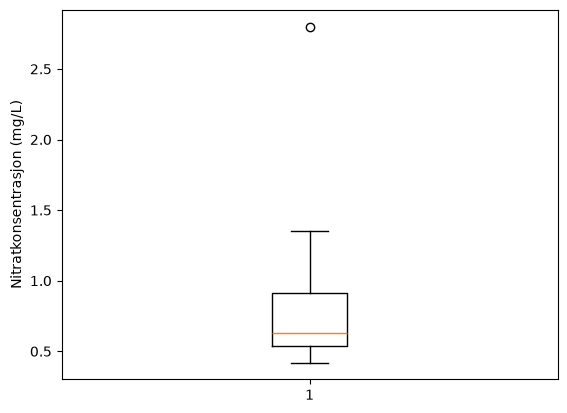

In [16]:
plt.boxplot(nitrat)
plt.ylabel("Nitratkonsentrasjon (mg/L)")
plt.show()

<div class="diskuter">

**Diskuter:** Hva betyr det at en bekk ligger over 75-persentilen? Hvorfor er gjennomsnittet høyere enn medianen her?

</div>

### Boksplott
Et boksplott viser de samme størrelsene grafisk.

<div class="viktig">

<div class="bilde-midt" style="width:90%">

![Annotert boksplott](bilder/boksplott_forklart.png)

</div>

Boksen inneholder de midterste 50 % av målingene. Faktoren 1,5 for værhårene er en konvensjon, og punkter utenfor må undersøkes før vi eventuelt fjerner dem.

</div>

## Del 4: Hvor mye varierer dataene?

| Størrelse | Definisjon | Påvirkes av ekstreme verdier? |
|---|---|---|
| Variasjonsbredde | største minus minste verdi | svært mye |
| Interkvartilbredde (IQR) | $Q_3 - Q_1$ | lite |
| Standardavvik ($s$) | typisk avstand fra gjennomsnittet | ja |

In [17]:
IQR = q3 - q1
med = np.median(nitrat)
print(f"Konsentrasjon: {med:2f} +- {IQR:.2f}")

Konsentrasjon: 0.630000 +- 0.37


In [18]:
avvik = np.std(nitrat, ddof = 1)
snitt = np.mean(nitrat)
print(f"Konsentrasjon: {snitt:.2f} +- {avvik:.2f}")

Konsentrasjon: 0.88 +- 0.66


### Standardavvik

$$s=\sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}$$

Vi deler på $n-1$ fordi målingene er et utvalg. I NumPy må vi be om det med `ddof=1`. Uten `ddof=1` deler NumPy på $n$.

<div class="viktig">

Standardavviket har **samme enhet** som målingene og beskriver den *typiske* spredningen til **enkeltmålingene** rundt gjennomsnittet. Det betyr ikke at alle målingene ligger nøyaktig så langt fra gjennomsnittet.

</div>

### Relativt standardavvik (RSD)

$$RSD=\frac{s}{\bar{x}}\cdot 100\ \%$$

RSD setter spredningen i forhold til målenivået, og brukes mye for å sammenlikne presisjonen til analysemetoder.

<div class="oppgave">

**Prøv selv:** Skriv en funksjon `rsd(measurements)` som returnerer RSD i prosent. Test den på jernmålingene.

</div>

In [19]:
def rsd(measurements):
    x = np.mean(measurements)
    s = np.std(measurements, ddof = 1)
    return s/x * 100

print(f"RSD: {rsd(iron_mg_L):.2f} %")

RSD: 0.53 %


<div class="diskuter">

**Diskuter:** Metode A gir 1,0 mg/L med standardavvik 0,05 mg/L. Metode B gir 100 mg/L med standardavvik 0,20 mg/L. Hvilken metode har minst spredning, og hvilken har best relativ presisjon? Når blir RSD misvisende?

</div>

## Hva bruker vi når?

<div class="viktig">

| Situasjon | Nyttige størrelser |
|---|---|
| Gjentatte målinger av samme prøve, omtrent symmetrisk | gjennomsnitt og standardavvik |
| Mange ulike prøver med skjev fordeling | median og IQR |
| Sammenlikne presisjon ved ulike konsentrasjoner eller metoder | RSD |
| Hvor sikkert kjenner vi gjennomsnittet? | standardfeil eller konfidensintervall |

Dette er gode utgangspunkt, ikke automatiske regler.

</div>

<div class="diskuter">

Hvilke statistike størrelser ville du brukt for 1) seks bestemmelser av klorid i samme mineralvann, 2) nitrat i 80 brønner der noen få verdier er svært høye, 3) bly i jord fra ulike steder i et gammelt industriområde?

</div>

## Del 5: Hvor sikkert kjenner vi gjennomsnittet?

Gjentar vi hele forsøket med fem nye målinger, får vi et litt annet gjennomsnitt.

<div class="viktig">

- **Standardfeilen** $SE = s/\sqrt{n}$ beskriver hvor mye **gjennomsnittet** varierer fra forsøk til forsøk. Standardavviket beskriver **enkeltmålingene**.
- **95 % konfidensintervall:** $\bar{x} \pm t \cdot SE$. Metoden gir intervaller som inneholder det sanne gjennomsnittet omtrent 95 % av gangene.
- **t-faktoren** kommer fra Students t-fordeling og avhenger av $df = n-1$. Med få målinger er den stor: $t = 2{,}78$ for $n = 5$ og $t = 2{,}05$ for $n = 30$.

</div>

In [49]:
from scipy.stats import t
import scipy.stats as stats

n = len(iron_mg_L)
mean = np.mean(iron_mg_L)
sd = np.std(iron_mg_L, ddof = 1)
se = sd/np.sqrt(n)

nivå = 0.95
tfaktor = t.ppf((1 + nivå)/2,  n - 1)

nedre = mean - tfaktor*se
øvre = mean + tfaktor*se

print(f"{mean:.2f} mg/L, CI: [{nedre:.2f}, {øvre:.2f}]")

5.12 mg/L, CI: [5.08, 5.15]


In [53]:
# Funksjon som gjør mer av jobben for deg
ci = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
print(ci)

(np.float64(5.082452086150733), np.float64(5.149547913849267))


<div class="viktig">

Det er **metoden** som treffer omtrent 95 % av gangene. Et konfidensintervall er **ikke**

- området der 95 % av enkeltmålingene ligger
- en garanti mot systematiske feil: Er  f.eks. en standardløsning feil, kan vi få et smalt intervall rundt et gjennomsnitt som er feil

</div>

<div class="oppgave">

**Prøv selv:** Samle stegene i en funksjon som returnerer nedre og øvre grense for konfidensintervallet. Bruk den til å beregne 90 %, 95 % og 99 % konfidensintervall for jernmålingene.

</div>

<div class="diskuter">

<div class="bilde-hoyre" style="width:26%">

![Kyvetter](bilder/kyvetter.jpg)
<p class="kreditering"></p>

</div>

**Diskuter:** Hva skjer med bredden når konfidensnivået øker? Hva annet kan gjøre intervallet smalere? Hvorfor sier ti avlesninger av samme kyvette mindre om analysemetoden enn ti uavhengig preparerte løsninger?

</div>

## Rapportering og avrunding

<div class="viktig">

Oppgi usikkerheten med **maks to gjeldende sifre**, og avrund gjennomsnittet til **samme desimalplass** som usikkerheten. Behold full presisjon i beregningene, og avrund først når resultatet skal presenteres. Oppgi alltid hva usikkerheten er (SD, SE eller 95 % CI).

</div>

| Python gir | Rapporter |
|---|---|
| 5,1164 ± 0,02736 mg/L | 5,116 ± 0,027 mg/L |
| 5,1164 ± 0,03184 mg/L | 5,12 ± 0,03 mg/L |

<div class="diskuter">

Hvordan rapporterer du 0,60433 ± 0,003786 og 12,4150 ± 0,0271?

</div>

## Del 6: Feilstolper

Magnesium er målt ved fem konsentrasjoner, med tre replikater ved hver konsentrasjon. Radene er konsentrasjoner, og kolonnene er replikater. `axis=1` beregner langs hver rad.

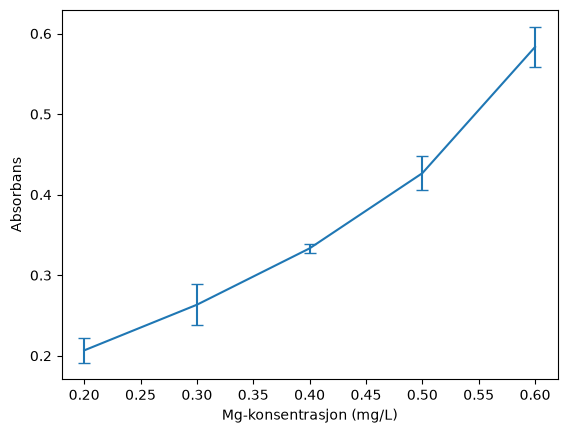

In [38]:
concentration_mg_L = np.array([0.2, 0.3, 0.4, 0.5, 0.6])
absorbance = np.array([
    [0.21, 0.22, 0.19],
    [0.26, 0.29, 0.24],
    [0.33, 0.33, 0.34],
    [0.41, 0.42, 0.45],
    [0.56, 0.61, 0.58],
])

mean_abs = np.mean(absorbance, axis = 1) # axis = 0: kolonne, axis = 1: rad
sd_abs = np.std(absorbance, axis = 1, ddof = 1)

plt.errorbar(concentration_mg_L, mean_abs, yerr = sd_abs, capsize = 4)
plt.xlabel("Mg-konsentrasjon (mg/L)")
plt.ylabel("Absorbans")
plt.show()

## Del 7: Statistikk med Pandas

Pandas har de samme metodene: `mean()`, `median()`, `std()`, `quantile()` og `describe()`. `std()` i Pandas deler på $n-1$ uten at vi må be om det. Vi bruker pingvindatasettet til å illustrere dette.

In [39]:
df = pd.read_csv("../datafiler/pengwings.txt")

In [42]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [45]:
print(df["bill_length_mm"].mean())  # Med Pandas
print(np.mean(df["bill_length_mm"]) # Med Numpy

43.9219298245614


__Oppgaver__:
1. Kobberkonsentrasjonen i åtte jordprøver er `[12, 14, 15, 16, 18, 21, 29, 47]` mg/kg. Beregn 25-, 50- og 75-persentilen, og forklar hvert resultat med ord. Lag et boksplott.
2. Beregn gjennomsnitt, median, variasjonsbredde og IQR for `[4.91, 5.03, 4.98, 5.01, 5.07]`. Legg til `5.80` og beregn på nytt. Hvilke størrelser påvirkes mest, og hvorfor?
3. Beregn gjennomsnitt, standardavvik, standardfeil og 95 % konfidensintervall for `[12.42, 12.38, 12.45, 12.41, 12.39, 12.44]` mg/L. Rapporter resultatet med riktig avrunding, og forklar to endringer i forsøket som kan gjøre intervallet smalere.
4. En student måler samme løsning ti ganger uten å ta kyvetten ut av instrumentet. En annen lager ti løsninger uavhengig av hverandre og måler hver én gang. Hvilke kilder til variasjon fanger de to forsøkene opp? Hvilket forsøk sier mest om presisjonen til analysemetoden?
5. Beregn 95 % konfidensintervall for bare de tre første målingene i oppgave 3, og sammenlikn med intervallet for alle seks. Forklar forskjellen ved hjelp av standardfeilen og t-faktoren.